In [1]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder

from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import (
    RandomForestClassifier,
    AdaBoostClassifier,
    GradientBoostingClassifier
)

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report,
    roc_auc_score,
    roc_curve
)

import joblib
import warnings

warnings.filterwarnings("ignore")

In [2]:
df = pd.read_csv("Customer Churn.csv")
print("Dataset loaded successfully!")

Dataset loaded successfully!


In [3]:
df.head()

,CustomerID,Count,Country,State,City,Zip Code,Lat Long,Latitude,Longitude,Gender,...,Contract,Paperless Billing,Payment Method,Monthly Charges,Total Charges,Churn Label,Churn Value,Churn Score,CLTV,Churn Reason
0,3668-QPYBK,1,United States,California,Los Angeles,90003,"33.964131, -118.272783",33.964131,-118.272783,Male,...,Month-to-month,Yes,Mailed check,53.85,108.15,Yes,1,86,3239,Competitor made better offer
1,9237-HQITU,1,United States,California,Los Angeles,90005,"34.059281, -118.30742",34.059281,-118.307420,Female,...,Month-to-month,Yes,Electronic check,70.70,151.65,Yes,1,67,2701,Moved
2,9305-CDSKC,1,United States,California,Los Angeles,90006,"34.048013, -118.293953",34.048013,-118.293953,Female,...,Month-to-month,Yes,Electronic check,99.65,820.5,Yes,1,86,5372,Moved
3,7892-POOKP,1,United States,California,Los Angeles,90010,"34.062125, -118.315709",34.062125,-118.315709,Female,...,Month-to-month,Yes,Electronic check,104.80,3046.05,Yes,1,84,5003,Moved
4,0280-XJGEX,1,United States,California,Los Angeles,90015,"34.039224, -118.266293",34.039224,-118.266293,Male,...,Month-to-month,Yes,Bank transfer (automatic),103.70,5036.3,Yes,1,89,5340,Competitor had better devices


In [4]:
df.tail()

,CustomerID,Count,Country,State,City,Zip Code,Lat Long,Latitude,Longitude,Gender,...,Contract,Paperless Billing,Payment Method,Monthly Charges,Total Charges,Churn Label,Churn Value,Churn Score,CLTV,Churn Reason
7038,2569-WGERO,1,United States,California,Landers,92285,"34.341737, -116.539416",34.341737,-116.539416,Female,...,Two year,Yes,Bank transfer (automatic),21.15,1419.4,No,0,45,5306,NaN
7039,6840-RESVB,1,United States,California,Adelanto,92301,"34.667815, -117.536183",34.667815,-117.536183,Male,...,One year,Yes,Mailed check,84.80,1990.5,No,0,59,2140,NaN
7040,2234-XADUH,1,United States,California,Amboy,92304,"34.559882, -115.637164",34.559882,-115.637164,Female,...,One year,Yes,Credit card (automatic),103.20,7362.9,No,0,71,5560,NaN
7041,4801-JZAZL,1,United States,California,Angelus Oaks,92305,"34.1678, -116.86433",34.167800,-116.864330,Female,...,Month-to-month,Yes,Electronic check,29.60,346.45,No,0,59,2793,NaN
7042,3186-AJIEK,1,United States,California,Apple Valley,92308,"34.424926, -117.184503",34.424926,-117.184503,Male,...,Two year,Yes,Bank transfer (automatic),105.65,6844.5,No,0,38,5097,NaN


In [5]:
print("Rows:", df.shape[0])
print("Columns:", df.shape[1])

Rows: 7043
Columns: 33


In [6]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 33 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   CustomerID         7043 non-null   object 
 1   Count              7043 non-null   int64  
 2   Country            7043 non-null   object 
 3   State              7043 non-null   object 
 4   City               7043 non-null   object 
 5   Zip Code           7043 non-null   int64  
 6   Lat Long           7043 non-null   object 
 7   Latitude           7043 non-null   float64
 8   Longitude          7043 non-null   float64
 9   Gender             7043 non-null   object 
 10  Senior Citizen     7043 non-null   object 
 11  Partner            7043 non-null   object 
 12  Dependents         7043 non-null   object 
 13  Tenure Months      7043 non-null   int64  
 14  Phone Service      7043 non-null   object 
 15  Multiple Lines     7043 non-null   object 
 16  Internet Service   7043 

In [7]:
df.describe()

,Count,Zip Code,Latitude,Longitude,Tenure Months,Monthly Charges,Churn Value,Churn Score,CLTV
count,7043.0,7043.000000,7043.000000,7043.000000,7043.000000,7043.000000,7043.000000,7043.000000,7043.000000
mean,1.0,93521.964646,36.282441,-119.798880,32.371149,64.761692,0.265370,58.699418,4400.295755
std,0.0,1865.794555,2.455723,2.157889,24.559481,30.090047,0.441561,21.525131,1183.057152
min,1.0,90001.000000,32.555828,-124.301372,0.000000,18.250000,0.000000,5.000000,2003.000000
25%,1.0,92102.000000,34.030915,-121.815412,9.000000,35.500000,0.000000,40.000000,3469.000000
50%,1.0,93552.000000,36.391777,-119.730885,29.000000,70.350000,0.000000,61.000000,4527.000000
75%,1.0,95351.000000,38.224869,-118.043237,55.000000,89.850000,1.000000,75.000000,5380.500000
max,1.0,96161.000000,41.962127,-114.192901,72.000000,118.750000,1.000000,100.000000,6500.000000


In [8]:
df.describe()

,Count,Zip Code,Latitude,Longitude,Tenure Months,Monthly Charges,Churn Value,Churn Score,CLTV
count,7043.0,7043.000000,7043.000000,7043.000000,7043.000000,7043.000000,7043.000000,7043.000000,7043.000000
mean,1.0,93521.964646,36.282441,-119.798880,32.371149,64.761692,0.265370,58.699418,4400.295755
std,0.0,1865.794555,2.455723,2.157889,24.559481,30.090047,0.441561,21.525131,1183.057152
min,1.0,90001.000000,32.555828,-124.301372,0.000000,18.250000,0.000000,5.000000,2003.000000
25%,1.0,92102.000000,34.030915,-121.815412,9.000000,35.500000,0.000000,40.000000,3469.000000
50%,1.0,93552.000000,36.391777,-119.730885,29.000000,70.350000,0.000000,61.000000,4527.000000
75%,1.0,95351.000000,38.224869,-118.043237,55.000000,89.850000,1.000000,75.000000,5380.500000
max,1.0,96161.000000,41.962127,-114.192901,72.000000,118.750000,1.000000,100.000000,6500.000000


In [9]:
missing_values = df.isnull().sum()
print(missing_values)

CustomerID              0
Count                   0
Country                 0
State                   0
City                    0
Zip Code                0
Lat Long                0
Latitude                0
Longitude               0
Gender                  0
Senior Citizen          0
Partner                 0
Dependents              0
Tenure Months           0
Phone Service           0
Multiple Lines          0
Internet Service        0
Online Security         0
Online Backup           0
Device Protection       0
Tech Support            0
Streaming TV            0
Streaming Movies        0
Contract                0
Paperless Billing       0
Payment Method          0
Monthly Charges         0
Total Charges           0
Churn Label             0
Churn Value             0
Churn Score             0
CLTV                    0
Churn Reason         5174
dtype: int64


In [10]:
missing_values = df.isnull().sum()
missing_values = missing_values[missing_values > 0]
print(missing_values)

Churn Reason    5174
dtype: int64


In [11]:
print("Number of duplicate rows:", df.duplicated().sum())

Number of duplicate rows: 0


In [12]:
df = df.drop_duplicates()
print("Shape after removing duplicates:", df.shape)

Shape after removing duplicates: (7043, 33)


In [13]:
print(df["Churn Label"].value_counts())

Churn Label
No     5174
Yes    1869
Name: count, dtype: int64


In [14]:
print(df["Churn Label"].value_counts(normalize=True) * 100)

Churn Label
No     73.463013
Yes    26.536987
Name: proportion, dtype: float64


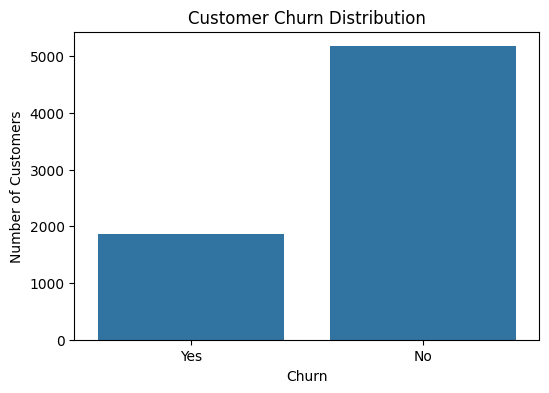

In [15]:
plt.figure(figsize=(6, 4))

sns.countplot(data=df, x="Churn Label")

plt.title("Customer Churn Distribution")
plt.xlabel("Churn")
plt.ylabel("Number of Customers")

plt.show()

In [16]:
print(df["Total Charges"].dtype)

object


In [17]:
df["Total Charges"] = pd.to_numeric(
    df["Total Charges"],
    errors="coerce"
)

In [18]:
print(df["Total Charges"].dtype)

float64


In [19]:
print(df.isnull().sum())

CustomerID              0
Count                   0
Country                 0
State                   0
City                    0
Zip Code                0
Lat Long                0
Latitude                0
Longitude               0
Gender                  0
Senior Citizen          0
Partner                 0
Dependents              0
Tenure Months           0
Phone Service           0
Multiple Lines          0
Internet Service        0
Online Security         0
Online Backup           0
Device Protection       0
Tech Support            0
Streaming TV            0
Streaming Movies        0
Contract                0
Paperless Billing       0
Payment Method          0
Monthly Charges         0
Total Charges          11
Churn Label             0
Churn Value             0
Churn Score             0
CLTV                    0
Churn Reason         5174
dtype: int64


In [20]:
drop_columns = [
    "CustomerID",
    "Churn Label",
    "Churn Value",
    "Churn Score",
    "Churn Reason"
]
df_model = df.drop(columns=drop_columns)
print(df_model.shape)

(7043, 28)


In [21]:
X = df_model
y = df["Churn Label"]
print("X shape:", X.shape)
print("y shape:", y.shape)

X shape: (7043, 28)
y shape: (7043,)


In [22]:
y = y.map({
    "No": 0,
    "Yes": 1
})

In [23]:
print(y.value_counts())

Churn Label
0    5174
1    1869
Name: count, dtype: int64


In [24]:
numeric_features = X.select_dtypes(
    include=["int64", "float64"]
).columns.tolist()

categorical_features = X.select_dtypes(
    include=["object"]
).columns.tolist()

print("Numerical Features:")
print(numeric_features)

print("\nCategorical Features:")
print(categorical_features)

Numerical Features:
['Count', 'Zip Code', 'Latitude', 'Longitude', 'Tenure Months', 'Monthly Charges', 'Total Charges', 'CLTV']

Categorical Features:
['Country', 'State', 'City', 'Lat Long', 'Gender', 'Senior Citizen', 'Partner', 'Dependents', 'Phone Service', 'Multiple Lines', 'Internet Service', 'Online Security', 'Online Backup', 'Device Protection', 'Tech Support', 'Streaming TV', 'Streaming Movies', 'Contract', 'Paperless Billing', 'Payment Method']


In [25]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

In [26]:
print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

Training data: (5634, 28)
Testing data: (1409, 28)


In [27]:
numeric_transformer = Pipeline(
    steps=[
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler())
    ]
)

In [28]:
categorical_transformer = Pipeline(
    steps=[
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("onehot", OneHotEncoder(
            handle_unknown="ignore",
            drop="first"
        ))
    ]
)

In [29]:
preprocessor = ColumnTransformer(
    transformers=[
        ("num", numeric_transformer, numeric_features),
        ("cat", categorical_transformer, categorical_features)
    ]
)

In [30]:
## Logistic Regression
logistic_model = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        ("classifier", LogisticRegression(
            max_iter=1000,
            random_state=42
        ))
    ]
)

In [31]:
logistic_model.fit(X_train, y_train)

,steps,"[('preprocessor', ...), ('classifier', ...)]"
,transform_input,None
,memory,None
,verbose,False
,transformers,"[('num', ...), ('cat', ...)]"
,remainder,'drop'
,sparse_threshold,0.3
,n_jobs,None
,transformer_weights,None
,verbose,False
,verbose_feature_names_out,True


In [32]:
y_pred_lr = logistic_model.predict(X_test)

In [33]:
print("Logistic Regression")

print(
    classification_report(
        y_test,
        y_pred_lr
    )
)

Logistic Regression
              precision    recall  f1-score   support

           0       0.84      0.88      0.86      1035
           1       0.62      0.53      0.57       374

    accuracy                           0.79      1409
   macro avg       0.73      0.71      0.72      1409
weighted avg       0.78      0.79      0.78      1409



In [34]:
lr_accuracy = accuracy_score(y_test, y_pred_lr)

print("Accuracy:", lr_accuracy)

Accuracy: 0.7877927608232789


In [35]:
decision_tree_model = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        ("classifier", DecisionTreeClassifier(
            max_depth=6,
            random_state=42
        ))
    ]
)

In [36]:
decision_tree_model.fit(X_train, y_train)

,steps,"[('preprocessor', ...), ('classifier', ...)]"
,transform_input,None
,memory,None
,verbose,False
,transformers,"[('num', ...), ('cat', ...)]"
,remainder,'drop'
,sparse_threshold,0.3
,n_jobs,None
,transformer_weights,None
,verbose,False
,verbose_feature_names_out,True


In [37]:
y_pred_dt = decision_tree_model.predict(X_test)

In [38]:
print("Decision Tree")

print(
    classification_report(
        y_test,
        y_pred_dt
    )
)

Decision Tree
              precision    recall  f1-score   support

           0       0.84      0.88      0.86      1035
           1       0.62      0.53      0.58       374

    accuracy                           0.79      1409
   macro avg       0.73      0.71      0.72      1409
weighted avg       0.78      0.79      0.79      1409



In [39]:
dt_accuracy = accuracy_score(
    y_test,
    y_pred_dt
)

print("Accuracy:", dt_accuracy)

Accuracy: 0.7913413768630234


In [40]:
random_forest_model = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        ("classifier", RandomForestClassifier(
            n_estimators=200,
            max_depth=10,
            random_state=42,
            n_jobs=-1
        ))
    ]
)

In [41]:
random_forest_model.fit(
    X_train,
    y_train
)

,steps,"[('preprocessor', ...), ('classifier', ...)]"
,transform_input,None
,memory,None
,verbose,False
,transformers,"[('num', ...), ('cat', ...)]"
,remainder,'drop'
,sparse_threshold,0.3
,n_jobs,None
,transformer_weights,None
,verbose,False
,verbose_feature_names_out,True


In [42]:
y_pred_rf = random_forest_model.predict(X_test)

In [43]:
print("Random Forest")

print(
    classification_report(
        y_test,
        y_pred_rf
    )
)

Random Forest
              precision    recall  f1-score   support

           0       0.74      1.00      0.85      1035
           1       0.92      0.03      0.06       374

    accuracy                           0.74      1409
   macro avg       0.83      0.52      0.46      1409
weighted avg       0.79      0.74      0.64      1409



In [44]:
rf_accuracy = accuracy_score(
    y_test,
    y_pred_rf
)

print("Accuracy:", rf_accuracy)

Accuracy: 0.7423704755145494


In [45]:
adaboost_model = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        ("classifier", AdaBoostClassifier(
            n_estimators=100,
            learning_rate=0.8,
            random_state=42
        ))
    ]
)

In [46]:
adaboost_model.fit(
    X_train,
    y_train
)

,steps,"[('preprocessor', ...), ('classifier', ...)]"
,transform_input,None
,memory,None
,verbose,False
,transformers,"[('num', ...), ('cat', ...)]"
,remainder,'drop'
,sparse_threshold,0.3
,n_jobs,None
,transformer_weights,None
,verbose,False
,verbose_feature_names_out,True


In [47]:
y_pred_ab = adaboost_model.predict(X_test)

In [48]:
print("AdaBoost")
print(
    classification_report(
        y_test,
        y_pred_ab
    )
)

AdaBoost
              precision    recall  f1-score   support

           0       0.83      0.91      0.87      1035
           1       0.66      0.50      0.57       374

    accuracy                           0.80      1409
   macro avg       0.75      0.70      0.72      1409
weighted avg       0.79      0.80      0.79      1409



In [49]:
ab_accuracy = accuracy_score(
    y_test,
    y_pred_ab
)
print("Accuracy:", ab_accuracy)

Accuracy: 0.7998580553584103


In [50]:
gradient_boosting_model = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        ("classifier", GradientBoostingClassifier(
            n_estimators=100,
            learning_rate=0.1,
            max_depth=3,
            random_state=42
        ))
    ]
)

In [51]:
gradient_boosting_model.fit(
    X_train,
    y_train
)

,steps,"[('preprocessor', ...), ('classifier', ...)]"
,transform_input,None
,memory,None
,verbose,False
,transformers,"[('num', ...), ('cat', ...)]"
,remainder,'drop'
,sparse_threshold,0.3
,n_jobs,None
,transformer_weights,None
,verbose,False
,verbose_feature_names_out,True


In [52]:
y_pred_gb = gradient_boosting_model.predict(X_test)

In [53]:
print("Gradient Boosting")
print(
    classification_report(
        y_test,
        y_pred_gb
    )
)

Gradient Boosting
              precision    recall  f1-score   support

           0       0.84      0.91      0.87      1035
           1       0.67      0.51      0.58       374

    accuracy                           0.80      1409
   macro avg       0.75      0.71      0.72      1409
weighted avg       0.79      0.80      0.79      1409



In [54]:
gb_accuracy = accuracy_score(
    y_test,
    y_pred_gb
)
print("Accuracy:", gb_accuracy)

Accuracy: 0.8026969481902059


In [55]:
results = pd.DataFrame({
    "Model": [
        "Logistic Regression",
        "Decision Tree",
        "Random Forest",
        "AdaBoost",
        "Gradient Boosting"
    ],
    
    "Accuracy": [
        lr_accuracy,
        dt_accuracy,
        rf_accuracy,
        ab_accuracy,
        gb_accuracy
    ]
})
results

,Model,Accuracy
0,Logistic Regression,0.787793
1,Decision Tree,0.791341
2,Random Forest,0.742370
3,AdaBoost,0.799858
4,Gradient Boosting,0.802697


In [56]:
results = results.sort_values(
    by="Accuracy",
    ascending=False
)
results

,Model,Accuracy
4,Gradient Boosting,0.802697
3,AdaBoost,0.799858
1,Decision Tree,0.791341
0,Logistic Regression,0.787793
2,Random Forest,0.742370


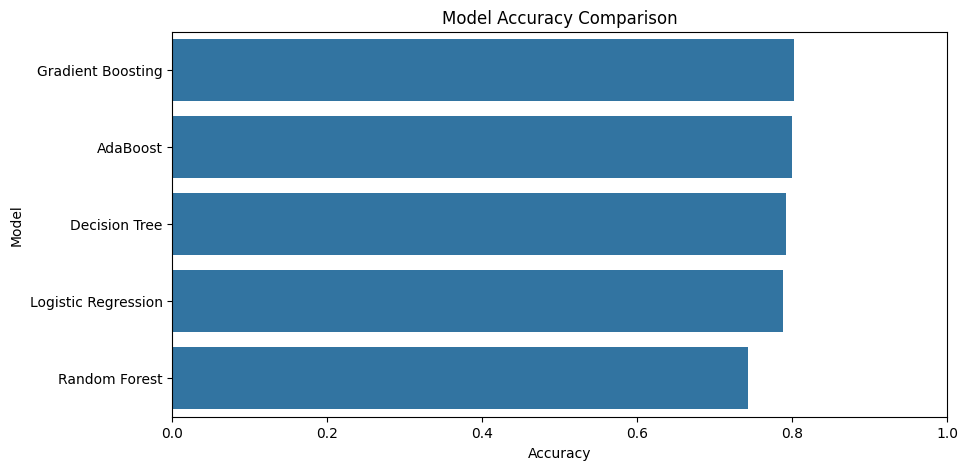

In [57]:
plt.figure(figsize=(10, 5))
sns.barplot(
    data=results,
    x="Accuracy",
    y="Model"
)
plt.title("Model Accuracy Comparison")
plt.xlim(0, 1)
plt.show()

In [58]:
def evaluate_model(model_name, y_true, y_pred, y_probability):
    accuracy = accuracy_score(y_true, y_pred)
    precision = precision_score(y_true, y_pred)
    recall = recall_score(y_true, y_pred)
    f1 = f1_score(y_true, y_pred)
    auc = roc_auc_score(y_true, y_probability) 
    return {
        "Model": model_name,
        "Accuracy": accuracy,
        "Precision": precision,
        "Recall": recall,
        "F1 Score": f1,
        "ROC AUC": auc
    }

In [59]:
lr_prob = logistic_model.predict_proba(X_test)[:, 1]

dt_prob = decision_tree_model.predict_proba(X_test)[:, 1]

rf_prob = random_forest_model.predict_proba(X_test)[:, 1]

ab_prob = adaboost_model.predict_proba(X_test)[:, 1]

gb_prob = gradient_boosting_model.predict_proba(X_test)[:, 1]

In [60]:
all_results = []

all_results.append(
    evaluate_model(
        "Logistic Regression",
        y_test,
        y_pred_lr,
        lr_prob
    )
)

all_results.append(
    evaluate_model(
        "Decision Tree",
        y_test,
        y_pred_dt,
        dt_prob
    )
)

all_results.append(
    evaluate_model(
        "Random Forest",
        y_test,
        y_pred_rf,
        rf_prob
    )
)

all_results.append(
    evaluate_model(
        "AdaBoost",
        y_test,
        y_pred_ab,
        ab_prob
    )
)

all_results.append(
    evaluate_model(
        "Gradient Boosting",
        y_test,
        y_pred_gb,
        gb_prob
    )
)

comparison_df = pd.DataFrame(all_results)

comparison_df

,Model,Accuracy,Precision,Recall,F1 Score,ROC AUC
0,Logistic Regression,0.787793,0.615385,0.534759,0.572246,0.833548
1,Decision Tree,0.791341,0.625000,0.534759,0.576369,0.831128
2,Random Forest,0.742370,0.923077,0.032086,0.062016,0.835614
3,AdaBoost,0.799858,0.663121,0.500000,0.570122,0.851116
4,Gradient Boosting,0.802697,0.670213,0.505348,0.576220,0.852927


In [61]:
comparison_df.sort_values(
    by="F1 Score",
    ascending=False
)

,Model,Accuracy,Precision,Recall,F1 Score,ROC AUC
1,Decision Tree,0.791341,0.625000,0.534759,0.576369,0.831128
4,Gradient Boosting,0.802697,0.670213,0.505348,0.576220,0.852927
0,Logistic Regression,0.787793,0.615385,0.534759,0.572246,0.833548
3,AdaBoost,0.799858,0.663121,0.500000,0.570122,0.851116
2,Random Forest,0.742370,0.923077,0.032086,0.062016,0.835614


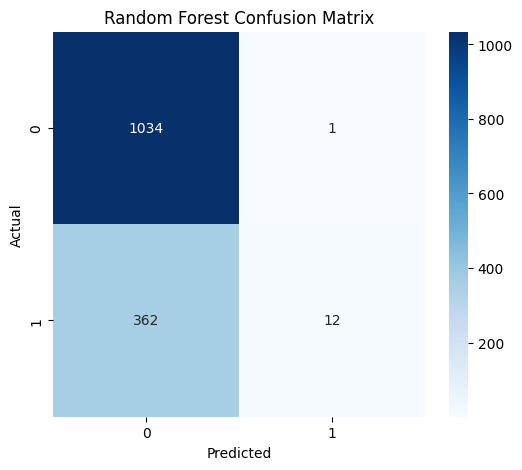

In [62]:
cm = confusion_matrix(
    y_test,
    y_pred_rf
)
plt.figure(figsize=(6, 5))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues"
)
plt.title("Random Forest Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()

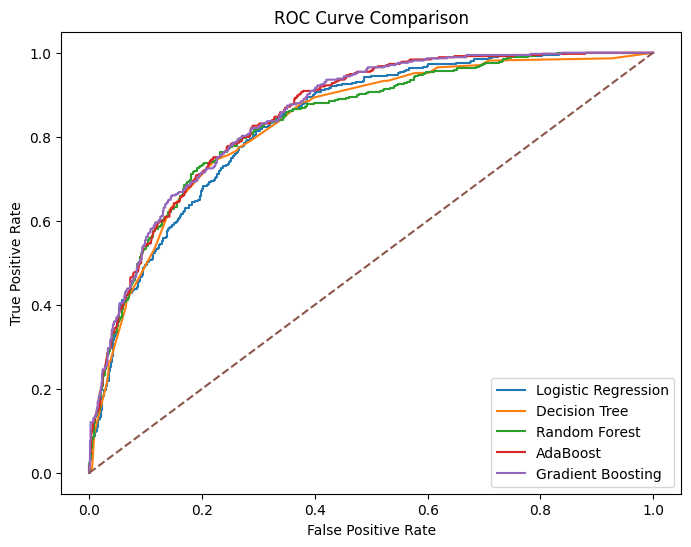

In [63]:
fpr_lr, tpr_lr, _ = roc_curve(y_test, lr_prob)
fpr_dt, tpr_dt, _ = roc_curve(y_test, dt_prob)
fpr_rf, tpr_rf, _ = roc_curve(y_test, rf_prob)
fpr_ab, tpr_ab, _ = roc_curve(y_test, ab_prob)
fpr_gb, tpr_gb, _ = roc_curve(y_test, gb_prob)
plt.figure(figsize=(8, 6))
plt.plot(
    fpr_lr,
    tpr_lr,
    label="Logistic Regression"
)
plt.plot(
    fpr_dt,
    tpr_dt,
    label="Decision Tree"
)
plt.plot(
    fpr_rf,
    tpr_rf,
    label="Random Forest"
)
plt.plot(
    fpr_ab,
    tpr_ab,
    label="AdaBoost"
)
plt.plot(
    fpr_gb,
    tpr_gb,
    label="Gradient Boosting"
)
plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--"
)
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve Comparison")
plt.legend()
plt.show()

In [64]:
best_model_name = comparison_df.loc[
    comparison_df["F1 Score"].idxmax(),
    "Model"
]
print("Best Model:", best_model_name)

Best Model: Decision Tree


In [65]:
models = {
    "Logistic Regression": logistic_model,
    "Decision Tree": decision_tree_model,
    "Random Forest": random_forest_model,
    "AdaBoost": adaboost_model,
    "Gradient Boosting": gradient_boosting_model
}
best_model = models[best_model_name]
print(best_model)

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='median')),
                                                                  ('scaler',
                                                                   StandardScaler())]),
                                                  ['Count', 'Zip Code',
                                                   'Latitude', 'Longitude',
                                                   'Tenure Months',
                                                   'Monthly Charges',
                                                   'Total Charges', 'CLTV']),
                                                 ('cat',
                                                  Pipeline(steps=[('imputer',
                                                                  

In [66]:
joblib.dump(
    best_model,
    "churn_model.pkl"
)
print("Model saved successfully!")

Model saved successfully!


In [67]:
joblib.dump(
    X.columns.tolist(),
    "feature_columns.pkl"
)
print("Feature columns saved successfully!")

Feature columns saved successfully!


In [68]:
loaded_model = joblib.load(
    "churn_model.pkl"
)
test_prediction = loaded_model.predict(
    X_test.iloc[:5]
)
print(test_prediction)

[0 1 0 1 0]


In [69]:
predicted_labels = np.where(
    test_prediction == 1,
    "Yes",
    "No"
)
print(predicted_labels)

['No' 'Yes' 'No' 'Yes' 'No']
